Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.7996 - loss: 0.8395 - val_accuracy: 0.9280 - val_loss: 0.3026
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9199 - loss: 0.2891 - val_accuracy: 0.9480 - val_loss: 0.1963
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9382 - loss: 0.2137 - val_accuracy: 0.9573 - val_loss: 0.1590
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9497 - loss: 0.1725 - val_accuracy: 0.9645 - val_loss: 0.1326
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.9581 - loss: 0.1435 - val_accuracy: 0.9693 - val_loss: 0.1173
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9655 - loss: 0.1213 - val_accuracy: 0.9702 - val_loss: 0.1048
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9703 - loss: 0.1041 - val_accuracy: 0.9728 - val_loss: 0.0951
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9752 - loss: 0.0893 - val_accuracy: 

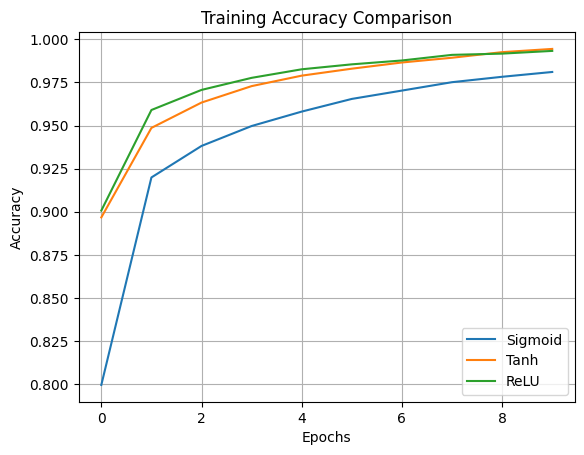

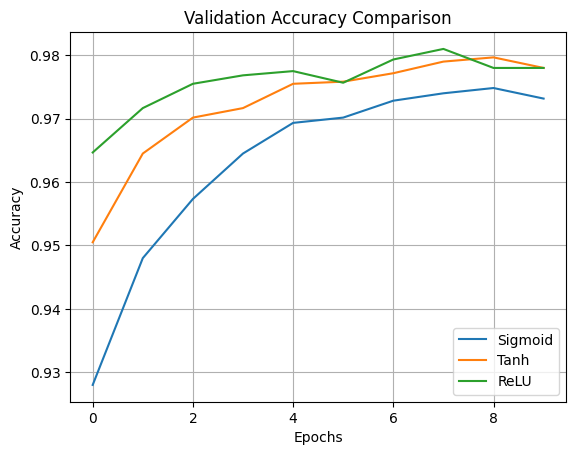

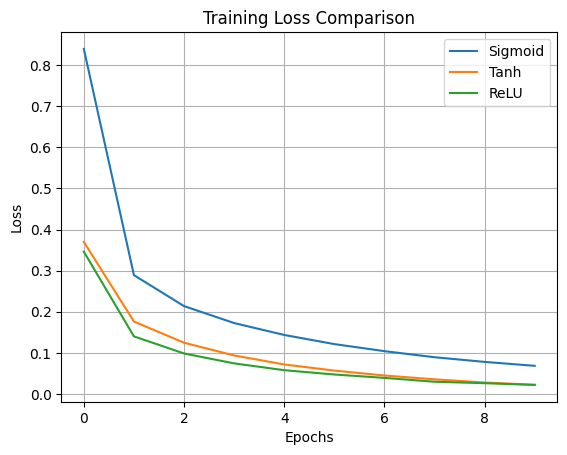

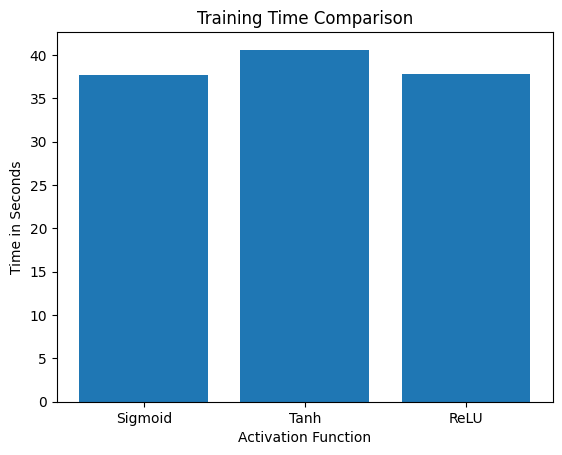

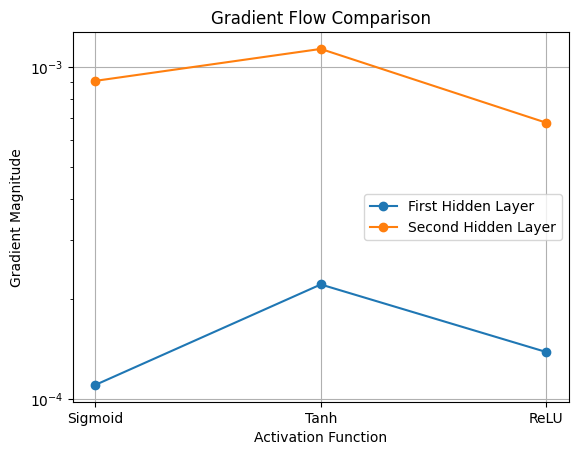


GRADIENT RESULTS
Sigmoid: 0.00011021421 0.0009055099
Tanh: 0.0002210298 0.0011298008
ReLU: 0.00013842806 0.0006776219

PROGRAM COMPLETED


In [7]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
import time

# 1. Load MNIST dataset
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

X_train = X_train / 255.0
X_test = X_test / 255.0

# 2. Create Sigmoid model
sigmoid_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='sigmoid'),
    tf.keras.layers.Dense(64, activation='sigmoid'),
    tf.keras.layers.Dense(10, activation='softmax')
])

sigmoid_model.compile(optimizer='adam',
                      loss='sparse_categorical_crossentropy',
                      metrics=['accuracy'])

start = time.time()
h1 = sigmoid_model.fit(X_train, y_train, epochs=10,
                       batch_size=128, validation_split=0.1)
sigmoid_time = time.time() - start

sigmoid_loss, sigmoid_acc = sigmoid_model.evaluate(X_test, y_test)


# 3. Create Tanh model
tanh_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='tanh'),
    tf.keras.layers.Dense(64, activation='tanh'),
    tf.keras.layers.Dense(10, activation='softmax')
])

tanh_model.compile(optimizer='adam',
                   loss='sparse_categorical_crossentropy',
                   metrics=['accuracy'])

start = time.time()
h2 = tanh_model.fit(X_train, y_train, epochs=10,
                    batch_size=128, validation_split=0.1)
tanh_time = time.time() - start

tanh_loss, tanh_acc = tanh_model.evaluate(X_test, y_test)


# 4. Create ReLU model
relu_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

relu_model.compile(optimizer='adam',
                   loss='sparse_categorical_crossentropy',
                   metrics=['accuracy'])

start = time.time()
h3 = relu_model.fit(X_train, y_train, epochs=10,
                    batch_size=128, validation_split=0.1)
relu_time = time.time() - start

relu_loss, relu_acc = relu_model.evaluate(X_test, y_test)


# 5. Print results
print("\nFINAL RESULTS")

print("Sigmoid Time:", round(sigmoid_time, 2), "seconds")
print("Tanh Time:", round(tanh_time, 2), "seconds")
print("ReLU Time:", round(relu_time, 2), "seconds")

print("\nTest Accuracy:")
print("Sigmoid:", round(sigmoid_acc * 100, 2), "%")
print("Tanh:", round(tanh_acc * 100, 2), "%")
print("ReLU:", round(relu_acc * 100, 2), "%")


# 6. Plot Training Accuracy
plt.plot(h1.history['accuracy'], label='Sigmoid')
plt.plot(h2.history['accuracy'], label='Tanh')
plt.plot(h3.history['accuracy'], label='ReLU')

plt.title("Training Accuracy Comparison")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()


# 7. Plot Validation Accuracy
plt.plot(h1.history['val_accuracy'], label='Sigmoid')
plt.plot(h2.history['val_accuracy'], label='Tanh')
plt.plot(h3.history['val_accuracy'], label='ReLU')

plt.title("Validation Accuracy Comparison")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()


# 8. Plot Training Loss
plt.plot(h1.history['loss'], label='Sigmoid')
plt.plot(h2.history['loss'], label='Tanh')
plt.plot(h3.history['loss'], label='ReLU')

plt.title("Training Loss Comparison")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()


# 9. Plot Training Time
names = ['Sigmoid', 'Tanh', 'ReLU']
times = [sigmoid_time, tanh_time, relu_time]

plt.bar(names, times)
plt.title("Training Time Comparison")
plt.xlabel("Activation Function")
plt.ylabel("Time in Seconds")
plt.show()


# 10. Calculate Gradients
def get_gradient(model):
    with tf.GradientTape() as tape:
        predictions = model(X_train[:100], training=True)
        loss = tf.keras.losses.sparse_categorical_crossentropy(
            y_train[:100], predictions)
        loss = tf.reduce_mean(loss)

    gradients = tape.gradient(loss, model.trainable_variables)

    # Weight gradients of hidden layers
    g1 = tf.reduce_mean(tf.abs(gradients[0])).numpy()
    g2 = tf.reduce_mean(tf.abs(gradients[2])).numpy()

    return g1, g2


sigmoid_g1, sigmoid_g2 = get_gradient(sigmoid_model)
tanh_g1, tanh_g2 = get_gradient(tanh_model)
relu_g1, relu_g2 = get_gradient(relu_model)


# 11. Plot Gradient Flow
early = [sigmoid_g1, tanh_g1, relu_g1]
later = [sigmoid_g2, tanh_g2, relu_g2]

plt.plot(names, early, marker='o', label='First Hidden Layer')
plt.plot(names, later, marker='o', label='Second Hidden Layer')

plt.yscale('log')
plt.title("Gradient Flow Comparison")
plt.xlabel("Activation Function")
plt.ylabel("Gradient Magnitude")
plt.legend()
plt.grid()
plt.show()


# 12. Print Gradient Values
print("\nGRADIENT RESULTS")

print("Sigmoid:", sigmoid_g1, sigmoid_g2)
print("Tanh:", tanh_g1, tanh_g2)
print("ReLU:", relu_g1, relu_g2)

print("\nPROGRAM COMPLETED")